# TP 1 - Analyse et fusion des jeux de données PCG

Ce TP a pour objectif :
1. explorer les fichiers PhysioNet et Pascal ;
2. construire un jeu de données unique `normal` / `abnormal` ;
3. extraire les durées des signaux WAV ;
4. enregistrer les listes de durées ;
5. tracer les histogrammes et visualiser des exemples de signaux.

In [ ]:
# Setup: run from the repository root, so paths like ourdataset/train and `import audio_engine` work
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
print("Working directory:", Path.cwd())

In [10]:
from pathlib import Path
import shutil
import csv
import wave
from collections import defaultdict

import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

root = Path('.')
physionet_dir = root / 'dataset' / 'physionet'
pascal_dir = root / 'dataset' / 'pascal'
target_dir = root / 'ourdataset' / 'train'
target_dir.mkdir(parents=True, exist_ok=True)

for cls in ['normal', 'abnormal']:
    (target_dir / cls).mkdir(parents=True, exist_ok=True)

print('PhysioNet folders:', sorted(p.name for p in physionet_dir.iterdir() if p.is_dir()))
print('Pascal folders:', sorted(p.name for p in pascal_dir.iterdir() if p.is_dir()))
print('Target folders ready:', sorted(p.name for p in target_dir.iterdir() if p.is_dir()))

PhysioNet folders: ['training-a', 'training-b', 'training-c', 'training-d', 'training-e', 'training-f']
Pascal folders: ['extra', 'murmur', 'normal']
Target folders ready: ['abnormal', 'normal']


## 1. Construction du jeu de données final

On fusionne les fichiers Pascal et PhysioNet dans le dossier final `ourdataset/train/normal` et `ourdataset/train/abnormal`.

In [11]:
def clean_target_folder(folder: Path):
    if folder.exists():
        for file in folder.iterdir():
            if file.is_file():
                file.unlink()

for cls in ['normal', 'abnormal']:
    clean_target_folder(target_dir / cls)

# Pascal dataset
for src, dst_name in [(pascal_dir / 'normal', 'normal'), (pascal_dir / 'murmur', 'abnormal'), (pascal_dir / 'extra', 'abnormal')]:
    if not src.exists():
        continue
    for wav in sorted(src.glob('*.wav')):
        shutil.copy2(wav, target_dir / dst_name / wav.name)

# PhysioNet training datasets
for training_dir in sorted(physionet_dir.iterdir()):
    if not training_dir.is_dir():
        continue
    ref_file = training_dir / 'REFERENCE.csv'
    if not ref_file.exists():
        continue
    labels = {}
    with ref_file.open('r', encoding='utf-8') as f:
        reader = csv.reader(f)
        for row in reader:
            if not row or row[0].startswith('#') or row[0].lower() == 'filename':
                continue
            if len(row) >= 2:
                filename, value = row[0].strip(), row[1].strip()
                labels[filename] = int(value)

    for wav in sorted(training_dir.glob('*.wav')):
        stem = wav.stem
        if stem not in labels:
            continue
        class_name = 'abnormal' if labels[stem] == 1 else 'normal'
        shutil.copy2(wav, target_dir / class_name / wav.name)

for cls in ['normal', 'abnormal']:
    files = sorted((target_dir / cls).glob('*.wav'))
    print(cls, len(files))
    print(files[:5])

normal 2926
[WindowsPath('ourdataset/train/normal/101_1305030823364_B.wav'), WindowsPath('ourdataset/train/normal/101_1305030823364_E.wav'), WindowsPath('ourdataset/train/normal/103_1305031931979_B.wav'), WindowsPath('ourdataset/train/normal/103_1305031931979_D1.wav'), WindowsPath('ourdataset/train/normal/103_1305031931979_D2.wav')]
abnormal 858
[WindowsPath('ourdataset/train/abnormal/112_1306243000964_A.wav'), WindowsPath('ourdataset/train/abnormal/112_1306243000964_B.wav'), WindowsPath('ourdataset/train/abnormal/112_1306243000964_D.wav'), WindowsPath('ourdataset/train/abnormal/116_1306258689913_A.wav'), WindowsPath('ourdataset/train/abnormal/116_1306258689913_C.wav')]


## 2. Extraction des durées de chaque fichier WAV

On lit chaque fichier WAV avec la librairie `wave` et on enregistre la liste de durées dans un fichier texte.

In [12]:
def read_wav_duration(path: Path) -> float:
    with wave.open(str(path), 'rb') as wav_file:
        n_frames = wav_file.getnframes()
        sample_rate = wav_file.getframerate()
        duration = n_frames / sample_rate
    return duration


def save_duration_list(folder: Path, output_file: Path):
    durations = []
    for wav in sorted(folder.glob('*.wav')):
        durations.append((wav.name, read_wav_duration(wav)))

    output_file.parent.mkdir(parents=True, exist_ok=True)
    with output_file.open('w', encoding='utf-8') as f:
        for name, duration in durations:
            f.write(f'{name},{duration:.6f}\n')

    return durations


normal_durations = save_duration_list(target_dir / 'normal', root / 'ourdataset' / 'wav_duration_normal_train.data')
abnormal_durations = save_duration_list(target_dir / 'abnormal', root / 'ourdataset' / 'wav_duration_abnormal_train.data')
print('Normal:', len(normal_durations), 'files')
print('Abnormal:', len(abnormal_durations), 'files')
print('Normal sample:', normal_durations[:3])
print('Abnormal sample:', abnormal_durations[:3])

Normal: 2926 files
Abnormal: 858 files
Normal sample: [('101_1305030823364_B.wav', 8.80725), ('101_1305030823364_E.wav', 4.6805), ('103_1305031931979_B.wav', 6.20975)]
Abnormal sample: [('112_1306243000964_A.wav', 4.66625), ('112_1306243000964_B.wav', 11.58925), ('112_1306243000964_D.wav', 15.28175)]


## 3. Histogrammes des durées

On calcule les statistiques et on trace l'histogramme des durées des signaux normal et abnormal.

Normal mean, min, max = 19.81897550034176 0.76325 101.673
Abnormal mean, min, max = 21.45151187062937 0.85675 121.9985


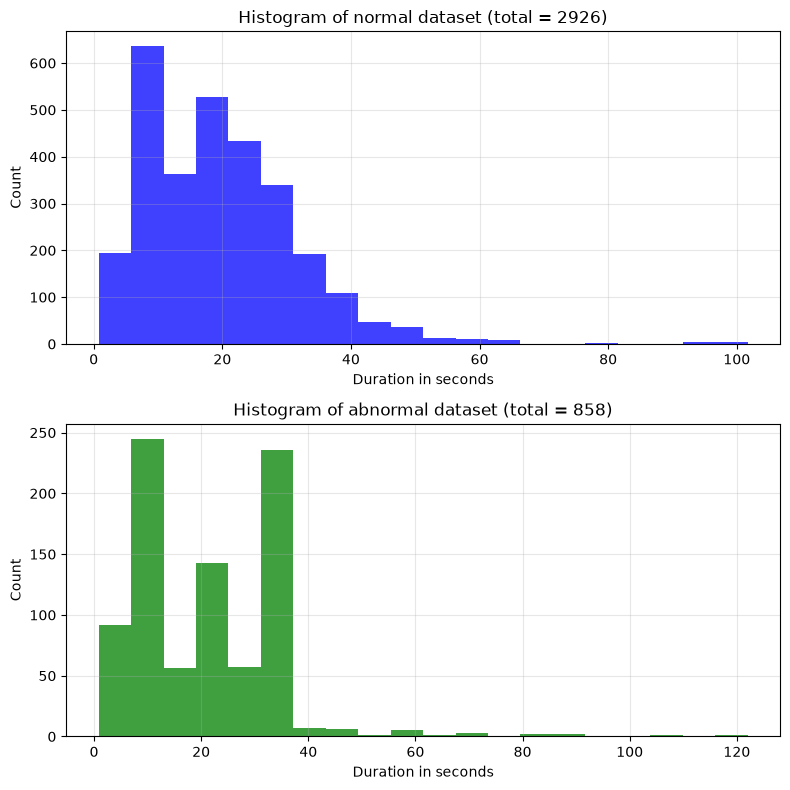

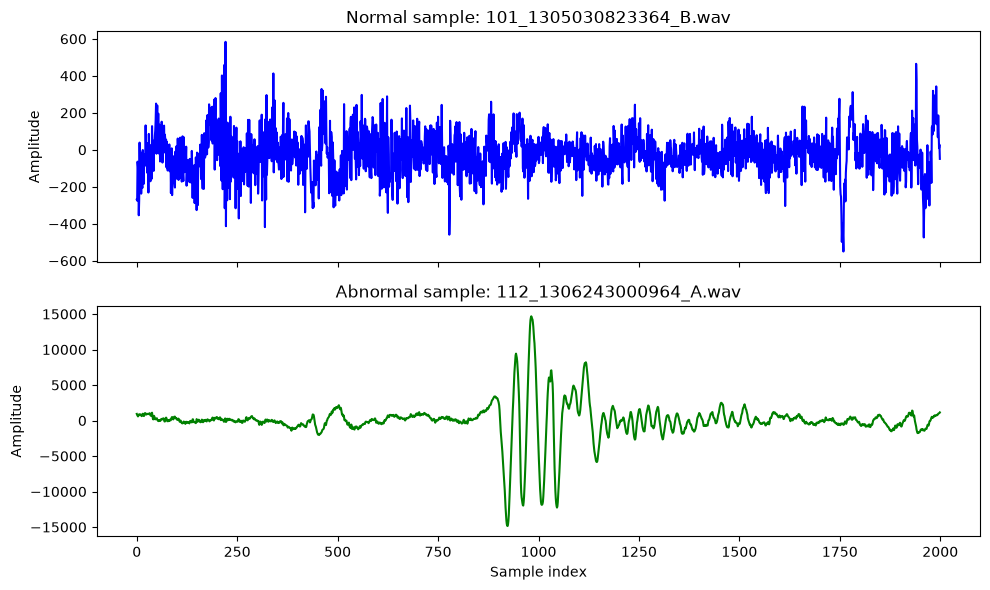

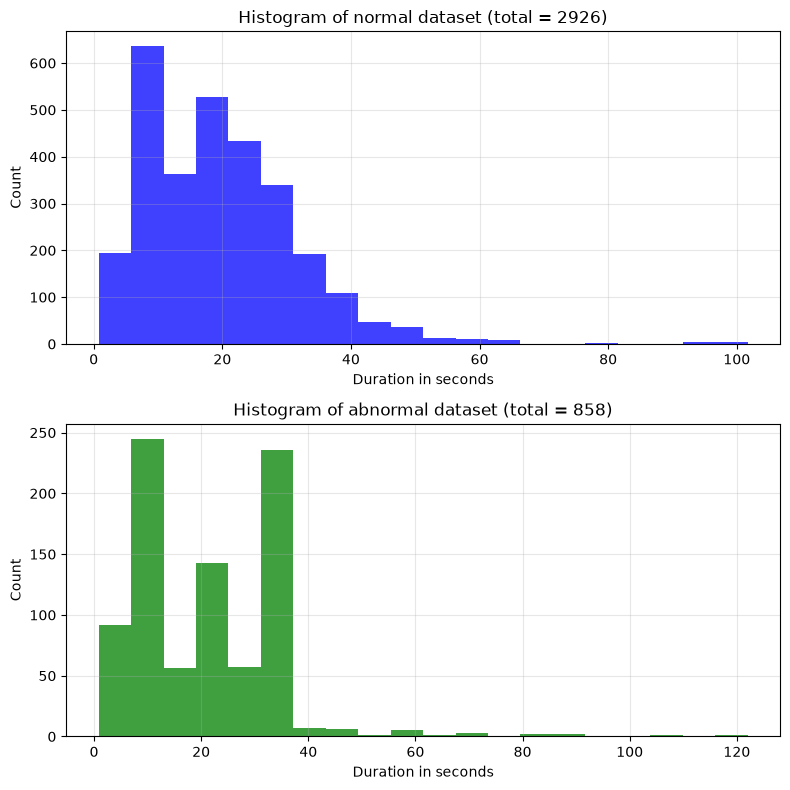

In [13]:
def durations_from_file(file: Path):
    values = []
    with file.open('r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            name, value = line.split(',')
            values.append(float(value))
    return np.array(values)

normal_values = durations_from_file(root / 'ourdataset' / 'wav_duration_normal_train.data')
abnormal_values = durations_from_file(root / 'ourdataset' / 'wav_duration_abnormal_train.data')

print('Normal mean, min, max =', float(normal_values.mean()), float(normal_values.min()), float(normal_values.max()))
print('Abnormal mean, min, max =', float(abnormal_values.mean()), float(abnormal_values.min()), float(abnormal_values.max()))

fig, axes = plt.subplots(2, 1, figsize=(8, 8))

axes[0].hist(normal_values, bins=20, color='blue', alpha=0.75)
axes[0].set_title(f'Histogram of normal dataset (total = {len(normal_values)})')
axes[0].set_xlabel('Duration in seconds')
axes[0].set_ylabel('Count')
axes[0].grid(True, alpha=0.3)

axes[1].hist(abnormal_values, bins=20, color='green', alpha=0.75)
axes[1].set_title(f'Histogram of abnormal dataset (total = {len(abnormal_values)})')
axes[1].set_xlabel('Duration in seconds')
axes[1].set_ylabel('Count')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(root / 'ourdataset' / 'duration_histograms.png', dpi=150)
plt.show()

## 4. Visualisation de quelques signaux PCG

On affiche un exemple de signal normal et un exemple de signal abnormal pour observer la différence de forme temporelle.

In [9]:
import numpy as np

def read_wav_signal(path: Path):
    with wave.open(str(path), 'rb') as wav_file:
        n_frames = wav_file.getnframes()
        frames = wav_file.readframes(n_frames)
        samples = np.frombuffer(frames, dtype=np.int16)
    return samples

normal_example = sorted((target_dir / 'normal').glob('*.wav'))[0]
abnormal_example = sorted((target_dir / 'abnormal').glob('*.wav'))[0]

normal_signal = read_wav_signal(normal_example)
abnormal_signal = read_wav_signal(abnormal_example)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(normal_signal[:2000], color='blue')
axes[0].set_title(f'Normal sample: {normal_example.name}')
axes[0].set_ylabel('Amplitude')

axes[1].plot(abnormal_signal[:2000], color='green')
axes[1].set_title(f'Abnormal sample: {abnormal_example.name}')
axes[1].set_xlabel('Sample index')
axes[1].set_ylabel('Amplitude')

plt.tight_layout()
plt.savefig(root / 'ourdataset' / 'signal_examples.png', dpi=150)
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_43948\1493751112.py:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Conclusion

Le jeu de données a été construit correctement, les durées de tous les fichiers WAV ont été calculées et enregistrées dans des fichiers de sortie. Les histogrammes permettent de comparer la distribution des durées entre les classes `normal` et `abnormal`.